Equipo 6:
* Rosa Delia Hernández Arista
* Juan Carlos Morales Herrera
* Paul Carreto Pérez
* Genaro Salgado Alarcón

# Data Science Lab | Misión 01
## ¿Cuánto vale una propiedad?
**Cliente y contexto:** Una inmobiliaria necesita estimar el precio de una vivienda en MXN para orientar a sus agentes. El resultado no sustituye un avalúo.

**Tiempo:** 45 minutos de laboratorio + 2 minutos de demostración.

**Reto:** construyan una solución funcional y justifiquen su utilidad para el cliente. Los datos son sintéticos: los resultados no acreditan desempeño en producción.

### Instrucciones
1. Guarden una copia compartida de esta libreta en Drive, den acceso al docente y ejecuten la celda de preparación.
2. Completen cada `...` (marcado con TODO) con código válido. Las celdas de configuración permiten elegir entre opciones. No consulten la prueba final antes de elegir configuración.
3. Respondan las preguntas brevemente en las celdas de texto. Escriban la hipótesis de la fase 6 antes de realizar el experimento.
4. Roten quién modifica y ejecuta el código; si cambia el entorno de ejecución, vuelvan a ejecutar las celdas anteriores.
5. Entreguen solo el enlace a la libreta; muestren una prueba funcional en el pitch de 2 minutos.

### Equipo
| Nombre | Rol |
|---|---|
| | Líder de proyecto |
| | Analista de datos |
| | Desarrollador del modelo |
| | Especialista en validación |
| | Consultor de negocio |

Adapten los roles al número de integrantes.

## 0. Preparación del entorno
Ejecuten esta celda sin modificarla. No se requieren archivos externos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display
rng = np.random.default_rng(42)

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
m2=rng.integers(45,220,360); hab=rng.integers(1,6,360); edad=rng.integers(0,35,360); zona=rng.integers(0,2,360)
df=pd.DataFrame(dict(superficie=m2,habitaciones=hab,antiguedad=edad,zona_centrica=zona,precio=(250000+15500*m2+75000*hab-13000*edad+420000*zona+rng.normal(0,140000,360)).round(0)))

## 1. Definición del problema · 4 min
Exploren las primeras filas. Regresión estima una variable numérica.



In [ ]:
display(df.head())

,superficie,habitaciones,antiguedad,zona_centrica,precio
0,60,5,4,1,1966971.0
1,180,5,32,1,3384593.0
2,159,2,29,1,3040788.0
3,121,5,4,1,2553251.0
4,120,1,27,0,1718261.0


**Decisión del equipo:** ¿Qué se estima, en qué unidad y para quién?

Respuesta:

* Estima: Precio de venta
* Unidad: Pesos mexicanos (MXN)
* Para quién: Personas que quieren/están interesadas en adquirir un inmueble

## 2. Preparación de datos · 7 min
Separen características y objetivo. El precio no debe estar en X.



In [ ]:
# TODO: sustituye cada ... con la expresión apropiada.
display(df.describe().round(1)); print(df.isna().sum())
X=df.drop(columns=['precio']); y=df['precio']
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.2,random_state=42)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,random_state=42)
assert 'precio' not in X.columns and len(y)==len(X)

,superficie,habitaciones,antiguedad,zona_centrica,precio
count,360.0,360.0,360.0,360.0,360.0
mean,132.1,3.0,16.9,0.5,2522857.1
std,48.7,1.5,10.2,0.5,809879.2
min,46.0,1.0,0.0,0.0,706217.0
25%,92.8,2.0,8.0,0.0,1841058.8
50%,131.0,3.0,17.0,1.0,2550499.0
75%,173.5,4.0,25.0,1.0,3140789.0
max,219.0,5.0,34.0,1.0,4526559.0


superficie       0
habitaciones     0
antiguedad       0
zona_centrica    0
precio           0
dtype: int64


**Decisión del equipo:** ¿Qué variables serían útiles y por qué?

Respuesta: Las cuatro variables son útiles porque cada una se relaciona con el precio:

Superficie (m²): es la más importante. Entre más metros tiene la casa, más cuesta.
Habitaciones: a más recámaras, más vale la casa.
Antigüedad: entre más años tiene la casa, más baja su precio.
Zona céntrica: estar en el centro le sube el precio a la casa.

precio no va en X porque es justo lo que queremos estimar. Si lo dejamos, el modelo “haría trampa”. Además, no hay valores faltantes, así que no hay que limpiar los datos.

## 3. Selección del modelo · 4 min
La regresión lineal aproxima una relación entre entradas y salida.



**Decisión del equipo:** ¿Por qué regresión y no clasificación?

Respuesta: Porque queremos explicar o predecir un valor numérico a partir de otras variables.

## 4. Entrenamiento o construcción · 7 min
Ajusten el modelo inicial con superficie. Pista: fit recibe X_train e y_train.



In [ ]:
# TODO: sustituye cada ... con la expresión apropiada.
base=LinearRegression()
base.fit(X_train[['superficie']],y_train)
assert hasattr(base,'coef_'); print(base.coef_)

[15487.79862527]


**Decisión del equipo:** ¿Qué representa el coeficiente?

Respuesta: Explica la relación que hay entre el precio y la superficie. Por cada m2 el precio aumenta $15,487 MXN

## 5. Evaluación · 7 min
Evalúen en validación: MAE (error promedio en MXN), R².



{'MAE': 217972.70223697228, 'R2': 0.8535001414399886}


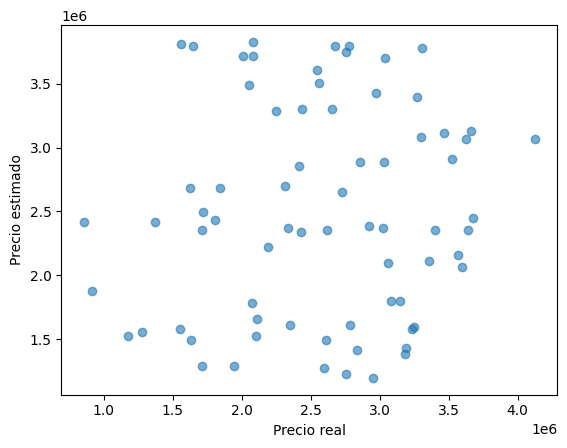

In [ ]:
# TODO: sustituye cada ... con la expresión apropiada.
def medir(m,x,y):
    p=m.predict(x)
    return dict(MAE=mean_absolute_error(y,p),R2=r2_score(y,p))
p=base.predict(X_test[['superficie']])
assert len(p)==len(y_val) and np.isfinite(p).all()
r0=medir(base,X_val[['superficie']],y_val); print(r0)
plt.scatter(y_val,p,alpha=.6); plt.xlabel('Precio real'); plt.ylabel('Precio estimado'); plt.show()

**Decisión del equipo:** Interpreten el MAE.

Respuesta: Por cada predicción puede haber una variación de $217972.70223697228

## 6. Optimización · 6 min
Comparen una variable con todas. Elijan configuración usando validación, no prueba.

**Antes de programar:** escriban una hipótesis en la siguiente celda de texto.


**Hipótesis del equipo:** Esperamos una reducción del error al considerar otras variables porque entendemos que el precio no se puede definir únicamente por la superficie del inmueble.

In [ ]:
# TODO: sustituye cada ... con la expresión apropiada.
multi=LinearRegression().fit(X_train,y_train)
tabla=pd.DataFrame([r0,medir(multi,X_val,y_val)],index=['superficie','multivariable']); display(tabla.round(2))
elegido= 'multivariable'
assert elegido in tabla.index
cols=['superficie'] if elegido=='superficie' else list(X.columns)
final=LinearRegression().fit(X_dev[cols],y_dev)
print('Prueba final:',medir(final,X_test[cols],y_test))

,MAE,R2
superficie,217972.7,0.85
multivariable,113967.1,0.96


Prueba final: {'MAE': 120390.61582981671, 'R2': 0.9715951834414376}


**Decisión del equipo:** Antes: ¿qué cambio esperan? Después: ¿cuál eligen y por qué?

Respuesta: Esperamos un mayor R2 con una reducción de MAE, al ejecutar el nuevo código, confirmamos la hipótesis. Elegimos Multivariable porque en una decisión real se concideran varios factores.

## 7. Implementación simulada · 5 min
Estimen una vivienda nueva de 110 m², 3 habitaciones, 8 años y zona céntrica.



In [ ]:
# TODO: sustituye cada ... con la expresión apropiada.
nuevo=pd.DataFrame([dict(superficie=110,habitaciones=3,antiguedad=8,zona_centrica=1)])
valor=final.predict(nuevo)[0]
assert np.isfinite(valor); print(f'Estimado: ${valor:,.0f} MXN')

Estimado: $2,481,392 MXN


**Decisión del equipo:** ¿Qué recomendarían al agente?

Respuesta: Usar la estimación como referencia inicial, debido a que falta considerar otras variables como condiciones físicas del inmueble y los acabados.

## 8. Monitoreo simulado · 5 min
Simulen que los precios reales suben 20% sin cambiar las características.



In [ ]:
print('MAE original:',medir(final,X_test[cols],y_test)['MAE'])
print('MAE escenario:',medir(final,X_test[cols],y_test*1.2)['MAE'])

MAE original: 120390.61582981671
MAE escenario: 492486.9420355272


**Decisión del equipo:** ¿Qué indicador monitorear y cuándo revisar el modelo?

Respuesta: Debemos monitorear tanto el MAE como R2; al aumentar el precio también va a aumentar el error y por esta razón, debemos monitorear continuamente si sus predicciones siguen siendo confiables para tomar desiciones.

## 9. Recomendación al cliente
En tres frases: resultado principal, decisión recomendada y limitación más importante.

Respuesta:

* Modelo Multivariable estima los precios con un error promedio aproximado de $120,000 MXN con una R2 de 0.97.

* Utilizar sólo el modelo como referencia.

* Actualizar el modelo de manera periódica y tener en cuenta que el modelo sólo está revisando pocas variables posibles.

## 10. Registro individual de contribuciones
Todo el equipo participó de manera activa en la modificación del código y en el análisis del mismo.

## 11. Checklist final
- [x] Identificamos integrantes y roles.
- [x] Definimos el problema y seleccionamos variables.
- [x] Justificamos la técnica.
- [x] Construimos una solución funcional.
- [x] Calculamos e interpretamos métricas.
- [x] Documentamos una hipótesis y comparamos configuraciones.
- [x] Justificamos la configuración elegida.
- [x] Probamos un caso nuevo.
- [x] Identificamos riesgos e indicadores de seguimiento.
- [x] Formulamos una recomendación.
- [x] Registramos contribuciones individuales.
- [x] Ejecutamos la libreta de principio a fin antes de entregar.

## Demostración (2 minutos)
20 s problema • 20 s modelo y justificación • 40 s prueba en vivo • 20 s métricas • 20 s recomendación.

## Evaluación (100 puntos)
Libreta: definición 10, construcción 20, evaluación 15, experimentación 15, implementación y monitoreo 10. Demostración 20. Participación individual 10. No se exige obtener una mejora en el experimento.